<a href="https://colab.research.google.com/github/brunokoskki/python_sis_26_2/blob/bruno_firakoski/Aula_12_Bruno_Firakoski/Aula_12_Bruno_Firakoski.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Etapa 1
!pip install openpyxl

from openpyxl import Workbook
from openpyxl.styles import PatternFill

planilha = Workbook()
aba = planilha.active
aba.title = "Servidores"

aba.append(["Hostname", "IP", "Memória (GB)", "Uso de Disco (%)", "Status"])
aba.append(["srv-web01", "192.168.0.10", 16, 45, "Online"])
aba.append(["srv-db01", "192.168.0.11", 64, 85, "Online"])
aba.append(["srv-app01", "192.168.0.12", 32, 80, "Online"])
aba.append(["srv-bkp01", "192.168.0.13", 8, 92, "Manutenção"])
aba.append(["srv-mail01", "192.168.0.14", 16, 60, "Offline"])

In [2]:
# Etapa 2
vermelho = PatternFill(start_color="FF9999", end_color="FF9999", fill_type="solid")

for linha in range(2, aba.max_row + 1):
    hostname = aba.cell(row=linha, column=1).value
    disco = aba.cell(row=linha, column=4).value
    if disco >= 80:
        aba.cell(row=linha, column=4).fill = vermelho
        print(f"ALERTA: {hostname} com {disco}% de disco, precisa de expansão de armazenamento.")

planilha.save("inventario_servidores.xlsx")

ALERTA: srv-db01 com 85% de disco, precisa de expansão de armazenamento.
ALERTA: srv-app01 com 80% de disco, precisa de expansão de armazenamento.
ALERTA: srv-bkp01 com 92% de disco, precisa de expansão de armazenamento.


In [4]:
# Etapa 3
registros = []

try:
    with open("log.txt", "r") as arquivo:
        for linha in arquivo:
            partes = linha.strip().split(" - ", 2)
            data_hora = partes[0]
            nivel = partes[1]
            mensagem = partes[2]
            registros.append([data_hora, nivel, mensagem])
            print("Nível:", nivel)
except FileNotFoundError:
    print("Arquivo log.txt não encontrado.")

Arquivo log.txt não encontrado.


In [5]:
# Etapa 4
planilha_log = Workbook()
aba_log = planilha_log.active
aba_log.title = "Logs"

aba_log.append(["Data/Hora", "Tipo de Evento", "Mensagem"])
for registro in registros:
    aba_log.append(registro)

planilha_log.save("auditoria_logs.xlsx")
print("Arquivo auditoria_logs.xlsx salvo.")

Arquivo auditoria_logs.xlsx salvo.


Atividade Prática 02 – Aula 12

In [6]:
# Etapa 1
import time

import psutil

cpu = psutil.cpu_percent(interval=1)
ram = psutil.virtual_memory().percent
print(f"CPU: {cpu}% | RAM: {ram}%")

CPU: 2.5% | RAM: 9.1%


In [7]:
# Etapa 2
psutil.cpu_percent()
for i in range(1, 6):
    time.sleep(1)
    cpu = psutil.cpu_percent()
    ram = psutil.virtual_memory().percent
    print(f"Iteração {i}: CPU {cpu}% | RAM {ram}%")

Iteração 1: CPU 3.5% | RAM 9.2%
Iteração 2: CPU 2.5% | RAM 9.2%
Iteração 3: CPU 2.5% | RAM 9.2%
Iteração 4: CPU 2.0% | RAM 9.2%
Iteração 5: CPU 20.2% | RAM 9.3%


In [8]:
# Etapa 3
caminho = "telemetria_sistema.csv"

with open(caminho, "w") as arquivo:
    arquivo.write("Iteracao,Uso_CPU_Pct,Uso_RAM_Pct\n")

In [9]:
# Etapa 4
psutil.cpu_percent()
for i in range(1, 6):
    time.sleep(1)
    cpu = psutil.cpu_percent()
    ram = psutil.virtual_memory().percent
    with open(caminho, "a") as arquivo:
        arquivo.write(f"{i},{cpu},{ram}\n")
    print(f"Iteração {i} gravada.")

Iteração 1 gravada.
Iteração 2 gravada.
Iteração 3 gravada.
Iteração 4 gravada.
Iteração 5 gravada.


Atividade Prática 03 – Aula 12

In [10]:
# Etapa 1
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("telemetria_sistema.csv")
print(df)

   Iteracao  Uso_CPU_Pct  Uso_RAM_Pct
0         1         31.2          9.2
1         2         33.7          9.3
2         3          2.5          9.3
3         4          2.5          9.3
4         5          3.5          9.3


In [11]:
# Etapa 2
media_cpu = df["Uso_CPU_Pct"].mean()
media_ram = df["Uso_RAM_Pct"].mean()
print(f"Média CPU: {media_cpu:.2f}%")
print(f"Média RAM: {media_ram:.2f}%")
print(df[["Uso_CPU_Pct", "Uso_RAM_Pct"]].describe())

Média CPU: 14.68%
Média RAM: 9.28%
       Uso_CPU_Pct  Uso_RAM_Pct
count     5.000000     5.000000
mean     14.680000     9.280000
std      16.250908     0.044721
min       2.500000     9.200000
25%       2.500000     9.300000
50%       3.500000     9.300000
75%      31.200000     9.300000
max      33.700000     9.300000


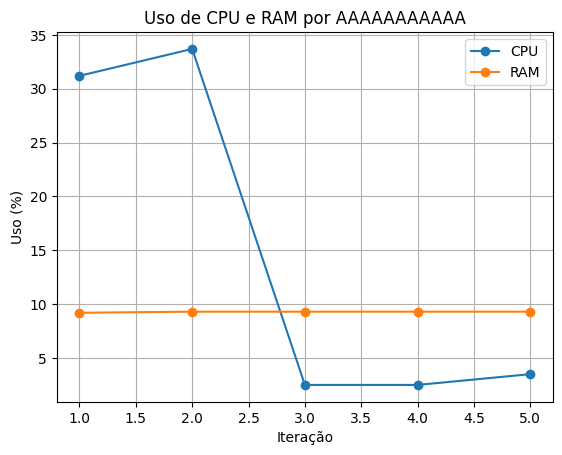

In [14]:
# Etapa 3
plt.plot(df["Iteracao"], df["Uso_CPU_Pct"], marker="o", label="CPU")
plt.plot(df["Iteracao"], df["Uso_RAM_Pct"], marker="o", label="RAM")
plt.title("Uso de CPU e RAM por iteração")
plt.xlabel("Iteração")
plt.ylabel("Uso (%)")
plt.legend()
plt.grid(True)
plt.show()